# D* Lite Replanning

Repair a route after a doorway closes while the robot is already partway along its journey.

D* Lite searches backwards from the goal. Each vertex stores a current cost and a one-step lookahead cost. A changed edge makes nearby vertices inconsistent. A priority queue propagates repairs until the current start has a consistent value. Moving the start updates the heuristic offset.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from planning import DStarLite, grid_search

## Close a doorway and repair the existing search

Compare the old path, the repaired route and the independent shortest length on the changed map. The search object is reused across the change.

Original steps 25 after closure 38 after reopening 20
Queue pops on initial plan and repair 26 287


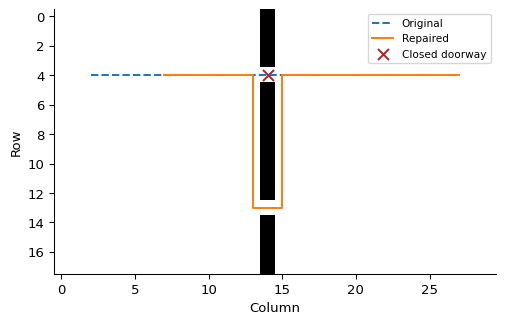

In [2]:
grid = np.zeros((18, 30), bool)
grid[:, 14] = True
grid[4, 14] = False
grid[13, 14] = False
start = (4, 2)
goal = (4, 27)
planner = DStarLite(grid, start, goal)
first_exp = planner.repair()
before = planner.path()
assert (4, 14) in before
moved = before[5]
planner.move_start(moved)
planner.change_cell((4, 14), True)
updates = planner.repair()
after = planner.path()
ref, _ = grid_search(planner.grid, moved, goal)
assert len(after) == len(ref) and (13, 14) in after and all(not planner.grid[p] for p in after)
planner.change_cell((4, 14), False)
planner.repair()
reopened = planner.path()
assert len(reopened) == len(grid_search(grid, moved, goal)[0])
print(
    "Original steps",
    len(before) - 1,
    "after closure",
    len(after) - 1,
    "after reopening",
    len(reopened) - 1,
)
print("Queue pops on initial plan and repair", first_exp, updates)
fig, ax = plt.subplots(figsize=(6.9, 3.3), constrained_layout=True)
ax.imshow(grid, cmap="Greys", vmin=0, vmax=1)
for points, label, style in [(before, "Original", "--"), (after, "Repaired", "-")]:
    y, x = np.array(points).T
    ax.plot(x, y, style, label=label)
ax.scatter(14, 4, marker="x", s=70, color="firebrick", label="Closed doorway")
ax.set(xlabel="Column", ylabel="Row")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

A repair can still require substantial work if the changed edge affects many shortest paths. The reference length also checks the response to reopening.

## Exercise

Close both doorways, check that the route becomes empty and reopen only the lower one.

## References

[Koenig and Likhachev, D* Lite (2002)](https://publications.ri.cmu.edu/d-lite)